<a href="https://colab.research.google.com/github/TianaT6/MSSP607/blob/main/Modules/Week_12/MSSP6070_Week12_Participation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 12 | Statistics and Hypothesis Testing

**Tianyi Tan · MSSP 6070**

Run all cells in order. In Colab, choose **Student Performance Data.csv** when
Part B prompts for the data.

[Class notebook](https://canvas.upenn.edu/courses/1936072/files/164012245?wrap=1) ·
[Student dataset](https://canvas.upenn.edu/courses/1936072/files/164012237?wrap=1)

I used generative AI to help draft and check the code and explanations.

# Part A. Class examples

These examples use the same distributions, sample sizes, and exam scores as
the instructor's notebook. Random seeds make the simulated plots repeatable.

In [18]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
import seaborn as sns
from statsmodels.stats.diagnostic import lilliefors
from IPython.display import display

sns.set(style='ticks')
alpha = 0.05

## A1. A lower-tail probability

The class example assumes a normal distribution with mean 3.5 kg and standard
deviation 0.76 kg. For an observation of 2.6 kg, I calculate the probability
of a value this low or lower under that model.

In [19]:
from scipy import stats
# Create normal distribution
nd = stats.norm(3.5, 0.76)

In [20]:
x = 2.6
p_value = nd.cdf(x)
print(f'Lower-tail probability: {p_value:.6f}')
if p_value < alpha:
    print('The observation is unusually low at the 0.05 level.')
else:
    print('The observation is not unusually low at the 0.05 level.')

Lower-tail probability: 0.118165
The observation is not unusually low at the 0.05 level.


## A2. Normal distribution curves

The first plot uses a normal distribution with mean 5 and standard deviation 2.
The next figure shows the PDF, CDF, survival function (SF), percent point
function (PPF), and inverse survival function (ISF) for a standard normal
distribution, as in the class example.

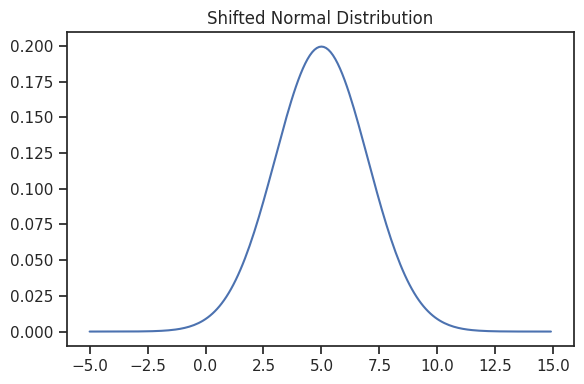

In [21]:
plt.figure(figsize=(6, 4))
'''PDF, scatter plot, and histogram.'''
# Generate the data
x = np.arange(-5,15,0.1)
# Plot a normal distribution: "Probability density functions"
myMean = 5
mySD = 2
y = stats.norm(myMean, mySD).pdf(x)
plt.plot(x,y)
#A shifted normal distribution is simply a normal distribution whose mean has been shifted by adding or subtracting a constant.
plt.title('Shifted Normal Distribution')
plt.tight_layout()
plt.show()

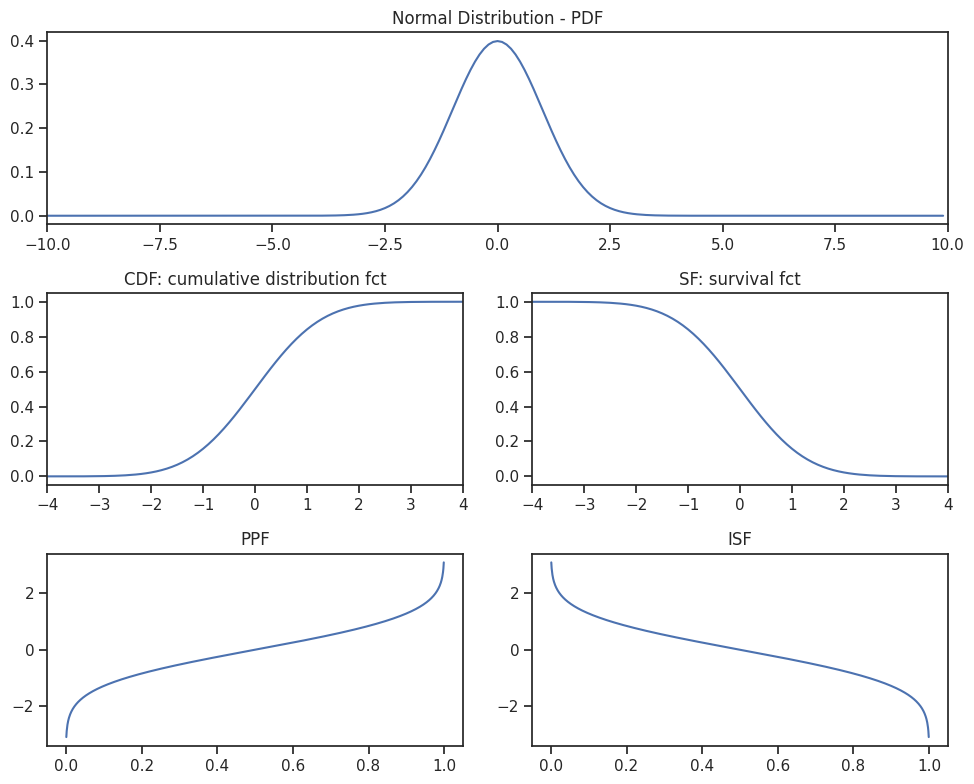

In [22]:
plt.figure(figsize=(10, 8))
''' Different aspects of a normal distribution'''
# Generate the data
x = np.r_[-10:10:0.1]
rv = stats.norm(0,1)   # random variate

x2 = np.linspace(0.001, 0.999, 999)

#A probability distribution function describes how probabilities are assigned to the possible values of a random variable.
#It tells you how likely each outcome is.
#A probability distribution function for a discrete random variable is called a probability mass function (PMF).
#A probability distribution function for a continuous random variable is called a probability density function (PDF).

ax = plt.subplot2grid((3,2),(0,0), colspan=2)
plt.plot(x,rv.pdf(x))
plt.xlim([-10,10])
plt.title('Normal Distribution - PDF')

plt.subplot(323)
plt.plot(x,rv.cdf(x))
plt.xlim([-4,4])
plt.title('CDF: cumulative distribution fct')

#In statistics and probability, the survival function of a random variable 𝑋 describes the probability that 𝑋
#takes a value greater than some threshold 𝑥.

plt.subplot(324)
plt.plot(x,rv.sf(x))
plt.xlim([-4,4])
plt.title('SF: survival fct')

#The Percent Point Function (PPF) is the inverse of the cumulative distribution function (CDF).

plt.subplot(325)
plt.plot(x2,rv.ppf(x2))
plt.title('PPF')

#The Inverse Survival Function (ISF) is the inverse of the survival function (SF) of a random variable.
plt.subplot(326)
plt.plot(x2,rv.isf(x2))
plt.title('ISF')
plt.tight_layout()
plt.show()

## A3. Simulated normal data

The class notebook plots 500 observations in sequence and then shows their
histogram. It next uses a sample of 100 observations for a histogram and
normal Q–Q plot.

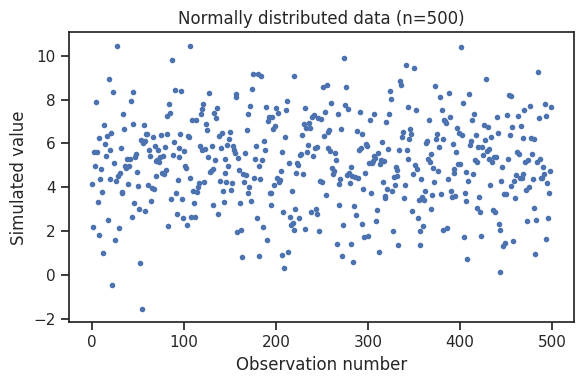

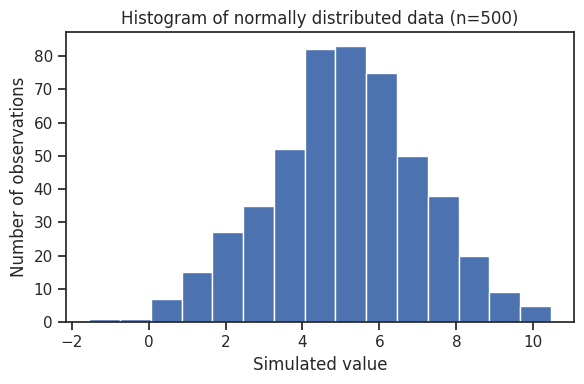

In [23]:
np.random.seed(2026)
numData = 500
data = stats.norm.rvs(myMean, mySD, size=numData)

plt.figure(figsize=(6, 4))
plt.plot(data, '.')
plt.title('Normally distributed data (n=500)')
plt.xlabel('Observation number')
plt.ylabel('Simulated value')
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
plt.hist(data, bins=15)
plt.title('Histogram of normally distributed data (n=500)')
plt.xlabel('Simulated value')
plt.ylabel('Number of observations')
plt.tight_layout()
plt.show()

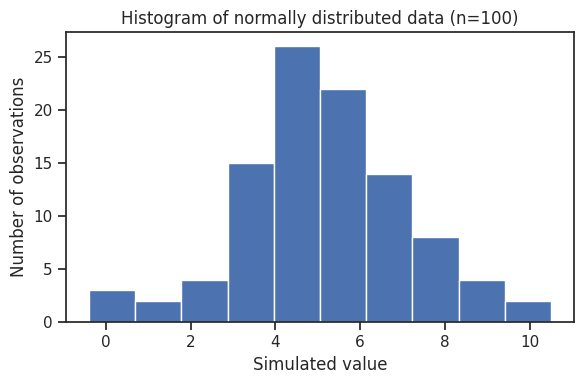

In [24]:
np.random.seed(2027)
numData = 100
data = stats.norm.rvs(myMean, mySD, size=numData)
plt.figure(figsize=(6, 4))
plt.hist(data, bins=10)
plt.title('Histogram of normally distributed data (n=100)')
plt.xlabel('Simulated value')
plt.ylabel('Number of observations')
plt.tight_layout()
plt.show()

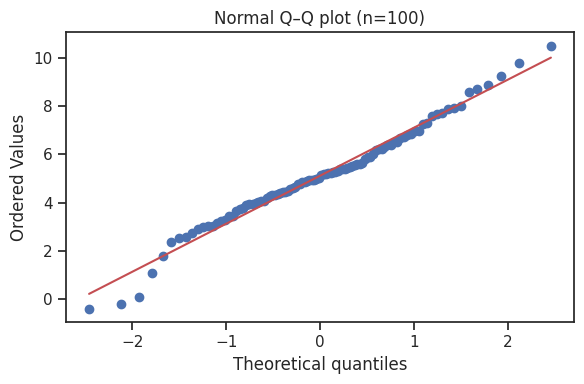

In [25]:
plt.figure(figsize=(6, 4))
stats.probplot(data, plot=plt)
plt.title('Normal Q–Q plot (n=100)')
plt.tight_layout()
plt.show()

## A4. Normality tests

This reproduces the class example with 1,000 simulated observations and seed
1234. It compares the omnibus, Shapiro–Wilk, Lilliefors, and Kolmogorov–Smirnov
(K–S) tests for the full sample and every tenth observation (100 values).

The ordinary K–S calculation is included for comparison with the example.
Its usual p-value is not calibrated when the mean and standard deviation are
estimated from the same data. Lilliefors accounts for estimated parameters.
See the [SciPy explanation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.goodness_of_fit.html#anti-pattern)
and [Lilliefors documentation](https://www.statsmodels.org/stable/generated/statsmodels.stats.diagnostic.lilliefors.html).

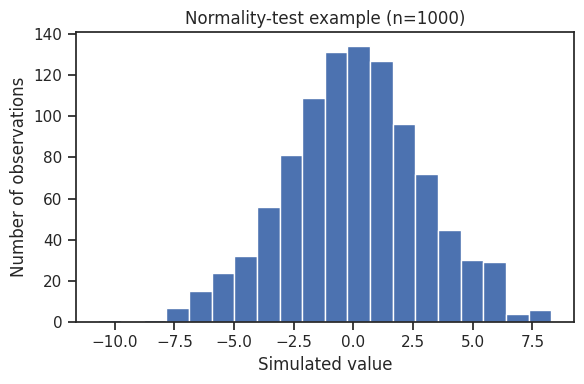

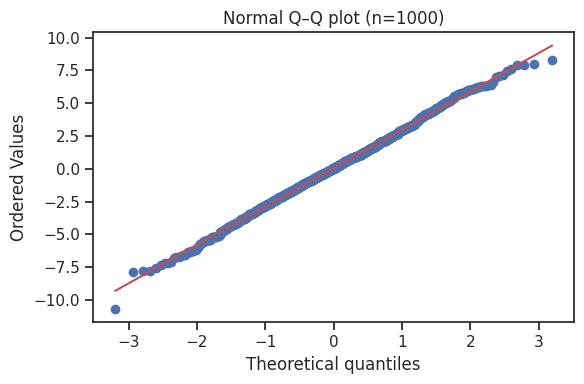

,All 1000 values,Every tenth value (n=100)
Omnibus,0.9137,0.6566
Shapiro–Wilk,0.5568,0.9203
Lilliefors,0.6712,0.3000
K–S (class calculation),0.8929,0.7087


A p-value above 0.05 means we do not reject normality; it does not prove normality.


In [26]:
np.random.seed(1234)
data = stats.norm.rvs(0, 3, size=1000)

plt.figure(figsize=(6, 4))
plt.hist(data, bins=20)
plt.title('Normality-test example (n=1000)')
plt.xlabel('Simulated value')
plt.ylabel('Number of observations')
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
stats.probplot(data, plot=plt)
plt.title('Normal Q–Q plot (n=1000)')
plt.tight_layout()
plt.show()

normality_results = pd.DataFrame(index=[
    'Omnibus', 'Shapiro–Wilk', 'Lilliefors', 'K–S (class calculation)'])
for label, sample in [('All 1000 values', data), ('Every tenth value (n=100)', data[::10])]:
    standardized = (sample - np.mean(sample)) / np.std(sample, ddof=1)
    normality_results[label] = [
        stats.normaltest(sample).pvalue,
        stats.shapiro(sample).pvalue,
        lilliefors(sample)[1],
        stats.kstest(standardized, 'norm').pvalue]
display(normality_results.round(4))
print('A p-value above 0.05 means we do not reject normality; it does not prove normality.')

The class notes also mention P–P plots. The supplied notebook does not have
separate P–P plotting code. Its `stats.probplot` calls produce normal Q–Q plots.

## A5. One-sample t-test

The class example compares 10 exam scores with a target mean of 110.

- **H0:** The population mean score is 110.
- **H1:** The population mean score is different from 110.

In [27]:
import numpy as np
scores = np.array([109.4, 76.2, 128.7, 93.7, 85.6, 117.7, 117.2, 87.3, 100.3, 55.11])

In [28]:
print('Normality-test p-value:', stats.normaltest(scores).pvalue)
print('Sample mean:', np.mean(scores))
print('Mean minus target:', np.mean(scores) - 110)

Normality-test p-value: 0.7882892827127141
Sample mean: 97.121
Mean minus target: -12.879000000000005


In [29]:
tval = (np.mean(scores) - 110) / stats.sem(scores)
td = stats.t(len(scores) - 1)
p = 2 * td.sf(abs(tval))
print(f't-statistic (sample minus target): {tval:.4f}')
print(f'Two-sided p-value: {p:.6f}')
if p < alpha:
    print('Reject H0 at 0.05.')
else:
    print('Fail to reject H0 at 0.05.')

t-statistic (sample minus target): -1.8361
Two-sided p-value: 0.099533
Fail to reject H0 at 0.05.


The p-value is about 0.0995. At 0.05, there is not enough evidence that the
population mean differs from 110. The class code reverses the subtraction
when calculating t. Here I use sample mean minus target and take the absolute
value for the two-sided p-value; the conclusion is the same.

# Part B. Participation activity

## 1. Read the student data

I use each student's average across math, reading, and writing as the overall score.
Each subject is scored out of 100 and gets the same weight.

In [ ]:
from pathlib import Path

csv_file = Path('Student Performance Data.csv')
if not csv_file.is_file():
    from google.colab import files

    uploaded = files.upload()
    if len(uploaded) != 1:
        raise ValueError('Upload one file: Student Performance Data.csv')
    csv_file = Path(next(iter(uploaded)))

students = pd.read_csv(csv_file)
score_columns = ['math score', 'reading score', 'writing score']
students['average_score'] = students[score_columns].mean(axis=1, skipna=False)

print(f'Student records: {len(students):,}')
print('Missing values in the three scores and grouping columns:',
      students[score_columns + ['gender', 'test preparation course']].isna().sum().sum())
print('Exact duplicate rows:', students.duplicated().sum())

## 2. Do male students who completed test preparation score differently?

The CSV records whether students completed the preparation **course**. I interpret
“others” as everyone outside the male-completer group. I also compare the two male
groups to see how the gap changes when the comparison is limited to males.

For each comparison, the null hypothesis is that the two population means are
equal, and the alternative is that they differ. I use a two-sided Welch t-test
at the 0.05 level. The test treats student
records as independent and allows the groups to have different variances.

In [ ]:
is_male = students['gender'].eq('male')
completed_prep = students['test preparation course'].eq('completed')

male_completed = students.loc[is_male & completed_prep, 'average_score']
everyone_else = students.loc[~(is_male & completed_prep), 'average_score']
no_prep = students['test preparation course'].eq('none')
male_no_prep = students.loc[is_male & no_prep, 'average_score']

def compare_means(first, second):
    test = stats.ttest_ind(first, second, equal_var=False)
    ci = test.confidence_interval(confidence_level=0.95)
    return {
        'Mean difference': f'{first.mean() - second.mean():.2f}',
        '95% CI': f'[{ci.low:.2f}, {ci.high:.2f}]',
        't': f'{test.statistic:.2f}',
        'p': f'{test.pvalue:.3g}',
    }

prep_groups = {
    'Males, completed prep': male_completed,
    'All other students': everyone_else,
    'Males, no prep': male_no_prep,
}
display(pd.DataFrame({
    label: group.agg(['count', 'mean', 'std'])
    for label, group in prep_groups.items()
}).T.astype({'count': int}).round(2))

display(pd.DataFrame({
    'Male completers vs. all others': compare_means(male_completed, everyone_else),
    'Male completers vs. other males': compare_means(male_completed, male_no_prep),
}).T)

**Yes.** Male completers averaged **70.78**, compared with **67.14** for all
other students. The difference was **3.65 points** (95% CI: 1.44 to 5.85,
*p* = 0.00127). The gap was larger within males, at **7.74 points**
(95% CI: 5.28 to 10.20, *p* = 1.73 × 10⁻⁹). Both comparisons reject equal
means at the 0.05 level. The groups may have differed in achievement before
taking the course, so these gaps alone cannot identify a causal effect.

In [ ]:
def check_distributions(groups, score_label):
    fig, axes = plt.subplots(2, len(groups), figsize=(3.7 * len(groups), 5.4))
    for column, (label, scores) in enumerate(groups.items()):
        axes[0, column].hist(scores, bins=range(0, 105, 5), density=True,
                             color='#477ca8', edgecolor='white')
        axes[0, column].set(title=label, xlim=(0, 100), xlabel=score_label,
                            ylabel='Density')
        stats.probplot(scores, dist='norm', plot=axes[1, column])
        axes[1, column].set(title='Normal Q–Q plot', ylim=(0, 105),
                            xlabel='Theoretical quantiles', ylabel=score_label)
        print(f'{label}: normality p = {stats.normaltest(scores).pvalue:.4f}')

    fig.tight_layout()
    plt.show()

check_distributions(prep_groups, 'Average score')

The Q–Q plots are fairly straight in the middle and bend at the ends. The
normality test detects a departure for all other students (*p* = 0.0011).
With at least 174 observations per group, Welch's test for the mean is less
sensitive to moderate departures from normality.

## 3. Reading scores by gender

I tested for a difference in mean reading scores between female and male
students. I also checked the group means within each preparation category
to see whether the overall gap was concentrated in one category.

In [ ]:
female_reading = students.loc[students['gender'].eq('female'), 'reading score']
male_reading = students.loc[is_male, 'reading score']

reading_groups = {'Female': female_reading, 'Male': male_reading}
display(pd.DataFrame({
    label: group.agg(['count', 'mean', 'std'])
    for label, group in reading_groups.items()
}).T.astype({'count': int}).round(2))

display(pd.DataFrame([compare_means(female_reading, male_reading)],
                     index=['Female vs. male']))

reading_by_prep = students.groupby(['test preparation course', 'gender'])[
    'reading score'
].mean().unstack()
reading_by_prep['Female minus male'] = reading_by_prep['female'] - reading_by_prep['male']
display(reading_by_prep.round(2))

Female students averaged **72.61** in reading and male students averaged
**65.47**, a gap of **7.14 points** (95% CI: 5.38 to 8.89,
*p* = 4.38 × 10⁻¹⁵). The observed gap was about **7.2 points** in each
preparation category. Those subgroup means are descriptive.

In [ ]:
check_distributions(reading_groups, 'Reading score')

The female reading Q–Q plot levels off near 100, the maximum score. The
normality test for that group also detects a departure (*p* < 0.001).
Both reading groups have over 480 students, which helps when comparing means.